Initial shape: (750, 9)
date            0
pm25           37
pm10            0
no2             0
o3              0
temperature     0
humidity       24
wind_speed      0
region          0
dtype: int64

Cleaned shape: (730, 21)
                      date        pm25        pm10         no2          o3  \
count                  730  730.000000  730.000000  730.000000  730.000000   
mean   2022-12-31 12:00:00   34.996176   56.910072   28.149810   40.209268   
min    2022-01-01 00:00:00    1.185211    1.783852    5.093751   11.200349   
25%    2022-07-02 06:00:00   26.454569   43.167946   22.461576   32.893691   
50%    2022-12-31 12:00:00   34.816967   56.788569   27.829139   40.059174   
75%    2023-07-01 18:00:00   43.300807   70.757342   34.040127   47.355919   
max    2023-12-31 00:00:00   68.570164  112.141436   51.407953   69.049262   
std                    NaN   12.913824   20.754691    8.769048   10.709230   

       temperature    humidity  wind_speed         year       month  \
c

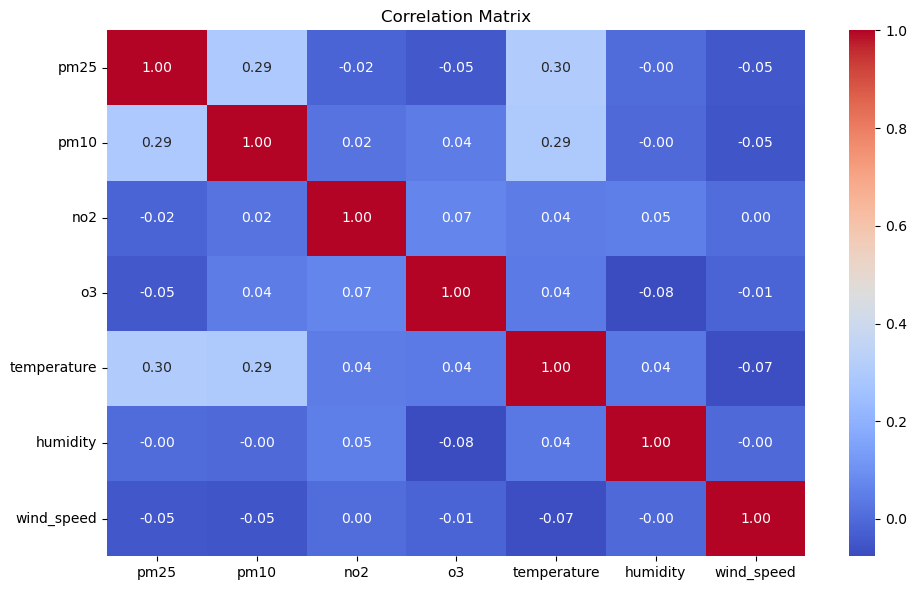

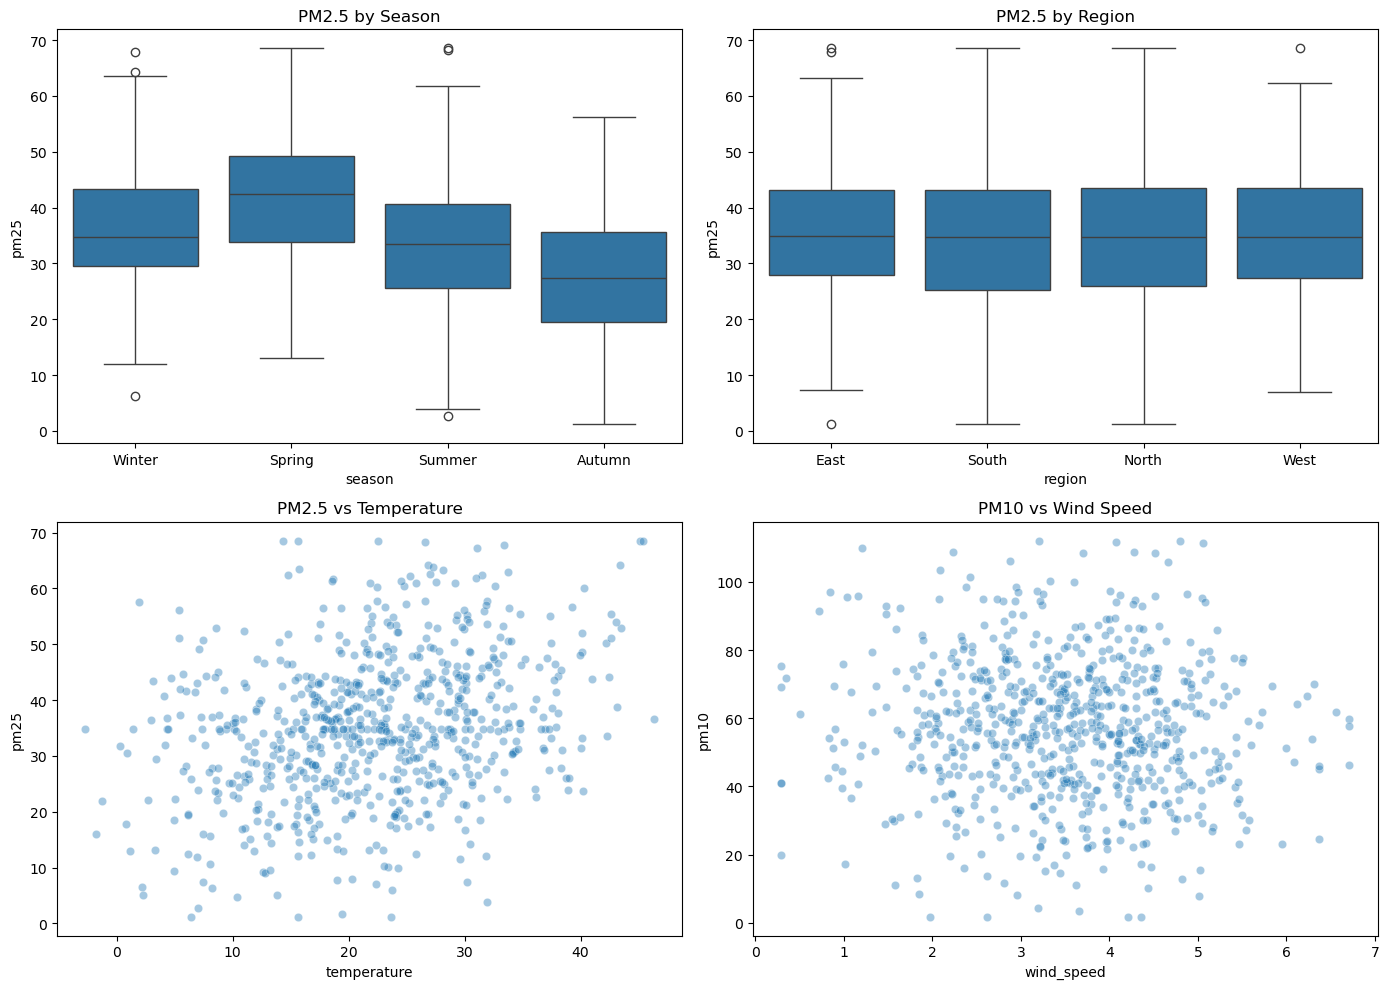


ANOVA PM2.5 by Season: F=50.264, p=0.00000
Pearson temperature vs PM2.5: r=0.303, p=0.00000
Pearson humidity vs PM2.5: r=-0.000, p=0.99842
Pearson wind_speed vs PM2.5: r=-0.050, p=0.17746


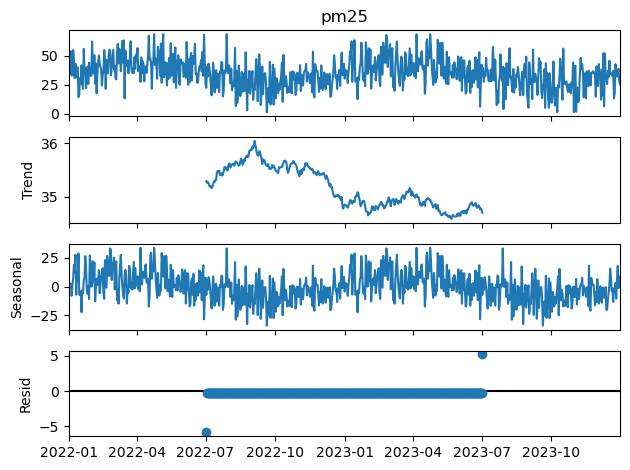

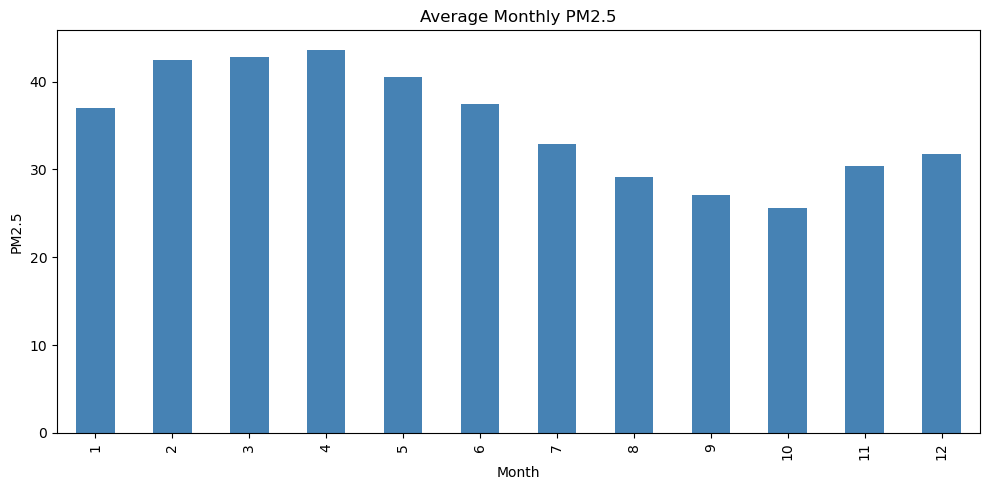


High-risk episode threshold (90th percentile): 52.01
Number of high-risk days: 73
season
Autumn     3
Spring    36
Summer    11
Winter    23
dtype: int64
region
East     13
North    18
South    20
West     22
dtype: int64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

dates = pd.date_range(start="2022-01-01", end="2023-12-31", freq="D")
n = len(dates)

data = pd.DataFrame({
    "date": dates,
    "pm25": np.random.normal(35, 12, n) + 10 * np.sin(np.arange(n) * 2 * np.pi / 365),
    "pm10": np.random.normal(55, 18, n) + 15 * np.sin(np.arange(n) * 2 * np.pi / 365),
    "no2": np.random.normal(28, 9, n),
    "o3": np.random.normal(40, 11, n),
    "temperature": np.random.normal(22, 7, n) + 8 * np.sin(np.arange(n) * 2 * np.pi / 365),
    "humidity": np.random.normal(60, 15, n),
    "wind_speed": np.random.normal(3.5, 1.2, n),
    "region": np.random.choice(["North", "South", "East", "West"], n)
})

data.loc[data.sample(frac=0.05).index, "pm25"] = np.nan
data.loc[data.sample(frac=0.03).index, "humidity"] = np.nan
data = pd.concat([data, data.sample(20)], ignore_index=True)

print("Initial shape:", data.shape)
print(data.isnull().sum())

data = data.drop_duplicates()

num_cols = ["pm25", "pm10", "no2", "o3", "temperature", "humidity", "wind_speed"]
imputer = SimpleImputer(strategy="median")
data[num_cols] = imputer.fit_transform(data[num_cols])

for col in num_cols:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    data[col] = np.clip(data[col], lower, upper)

data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["weekday"] = data["date"].dt.dayofweek
data["season"] = data["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

scaler = StandardScaler()
scaled = scaler.fit_transform(data[num_cols])
scaled_df = pd.DataFrame(scaled, columns=[c + "_scaled" for c in num_cols])
data = pd.concat([data.reset_index(drop=True), scaled_df], axis=1)

print("\nCleaned shape:", data.shape)
print(data.describe())

plt.figure(figsize=(10, 6))
sns.heatmap(data[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(x="season", y="pm25", data=data, ax=axes[0, 0])
axes[0, 0].set_title("PM2.5 by Season")
sns.boxplot(x="region", y="pm25", data=data, ax=axes[0, 1])
axes[0, 1].set_title("PM2.5 by Region")
sns.scatterplot(x="temperature", y="pm25", data=data, ax=axes[1, 0], alpha=0.4)
axes[1, 0].set_title("PM2.5 vs Temperature")
sns.scatterplot(x="wind_speed", y="pm10", data=data, ax=axes[1, 1], alpha=0.4)
axes[1, 1].set_title("PM10 vs Wind Speed")
plt.tight_layout()
plt.show()

seasonal_groups = [g["pm25"].values for _, g in data.groupby("season")]
f_stat, p_val = stats.f_oneway(*seasonal_groups)
print(f"\nANOVA PM2.5 by Season: F={f_stat:.3f}, p={p_val:.5f}")

for col in ["temperature", "humidity", "wind_speed"]:
    r, p = stats.pearsonr(data[col], data["pm25"])
    print(f"Pearson {col} vs PM2.5: r={r:.3f}, p={p:.5f}")

ts = data.set_index("date")["pm25"].sort_index()
ts = ts[~ts.index.duplicated(keep="first")]
ts = ts.asfreq("D").interpolate()

decomp = seasonal_decompose(ts, model="additive", period=365)
decomp.plot()
plt.tight_layout()
plt.show()

monthly = data.groupby("month")["pm25"].mean()
plt.figure(figsize=(10, 5))
monthly.plot(kind="bar", color="steelblue")
plt.title("Average Monthly PM2.5")
plt.xlabel("Month")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

threshold = data["pm25"].quantile(0.90)
high_risk = data[data["pm25"] > threshold]
print(f"\nHigh-risk episode threshold (90th percentile): {threshold:.2f}")
print(f"Number of high-risk days: {len(high_risk)}")
print(high_risk.groupby("season").size())
print(high_risk.groupby("region").size())